# 8 · Diffusion and score-based generation

**Question.** How can learning to remove noise support generation from noise?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/08-diffusion.ipynb)

Diffusion models train a reverse process for a known noising mechanism. We will fit a one-dimensional denoiser to a two-component Gaussian mixture, then run an explicit reverse chain. The example is small enough that we can also calculate the true noisy density's score and compare it with the learned function.

**Prerequisites:** Chapters 2 and 7, Gaussian conditioning, and gradients. **Outcomes:** simulate the forward marginal; distinguish noise prediction from direct observation reconstruction; derive the score relation; inspect a learned reverse sampler. No images, pretrained weights, or external datasets are required.

## Pipeline and framework

![Diffusion training constructs noisy observations from clean data at a random time and fits noise prediction; generation starts at noise and repeatedly applies reverse updates. Remember: add noise to train, remove noise to generate.](https://chikuang.github.io/teaching/genai/_static/diagrams/08-diffusion.png)

The forward and reverse arrows describe different computations. During training we can sample $x_t$ directly from $x_0$ and a time index; we do not need to run the entire forward chain for every minibatch. During generation we have no clean observation, so the learned denoiser must support a sequence of reverse updates.

| Stage | Known or learned object | Check |
|:--|:--|:--|
| Choose schedule | Fixed noise variances and cumulative products | Values stay in their valid ranges; the terminal distribution is sufficiently close to the initialization approximation. |
| Make a training pair | Clean $x_0$, random $t$, sampled noise, computed $x_t$ | The regression target is the exact noise used to construct that example. |
| Fit the denoiser | A time-conditioned neural function | The same time convention and schedule are used in fitting and sampling. |
| Run the reverse chain | A sampled trajectory from $x_T$ to $x_0$ | Apply the correct variance and final-step convention; compare generated and target distributions. |

In the one-dimensional mixture example, the exact score is available as an extra diagnostic. It lets us distinguish poor regression from a poorly implemented reverse update. A realistic image model usually lacks that oracle, so component tests and distributional evaluation become more important. Conditioning adds an observed input to the denoiser; it does not reverse the direction of the sampling loop.

## 8.1 · A known forward process

Index transitions by $t=1,\ldots,T$. Define $\alpha_t=1-\beta_t$ and $\bar\alpha_t=\prod_{s=1}^t\alpha_s$. The forward Markov transition is

$$
q(x_t\mid x_{t-1})=N(\sqrt{\alpha_t}x_{t-1},\beta_t I).
$$

Gaussian composition gives a direct marginal draw:

$$
x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,
\qquad \epsilon\sim N(0,I).
$$

Equation [(8.1)](https://chikuang.github.io/teaching/genai/chapters/08-diffusion.html#equation-eq-forward-noise) lets training sample a random time and generate its noisy observation without running every earlier transition. The schedule below leaves little signal at its final time. Starting the reverse chain at a standard normal is still an approximation unless the terminal forward marginal is exactly that normal distribution.

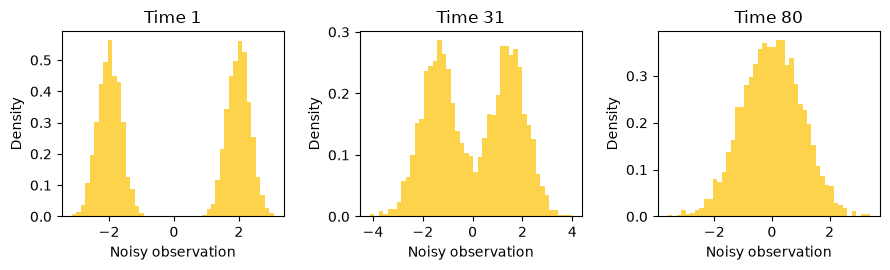

Final cumulative signal coefficient: 0.0153


In [1]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.set_num_threads(1)
torch.manual_seed(8)
T = 80
beta = torch.linspace(0.001, 0.10, T)
alpha = 1 - beta
alpha_bar = torch.cumprod(alpha, dim=0)

def data_sample(n):
    sign = 2 * torch.randint(0, 2, (n, 1)).float() - 1
    return 2 * sign + 0.35 * torch.randn(n, 1)

def noisy_sample(x0, t):
    noise = torch.randn_like(x0)
    a = alpha_bar[t, None]
    return a.sqrt() * x0 + (1-a).sqrt() * noise, noise

x0 = data_sample(3000)
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8))
for ax, index in zip(axes, [0, 30, T-1]):
    xt, _ = noisy_sample(x0, torch.full((len(x0),), index))
    ax.hist(xt.numpy().ravel(), bins=45, density=True, color='#fed34c')
    ax.set(title=f'Time {index+1}', xlabel='Noisy observation', ylabel='Density')
plt.tight_layout()
plt.show()
print('Final cumulative signal coefficient:', round(float(alpha_bar[-1]), 4))

Python uses index zero for mathematical time one. Keeping this distinction explicit avoids off-by-one errors in the reverse variance and the final denoising step.

> **Example 8.1 · One noisy observation has many possible origins**
>
> **Setup.** At one time, let $\bar\alpha_t=0.64$, so the signal multiplier is $0.8$ and the noise multiplier is $0.6$.
>
> **Work it through.** With clean value $x_0=2$ and sampled noise $\epsilon=-1$, Equation [(8.1)](https://chikuang.github.io/teaching/genai/chapters/08-diffusion.html#equation-eq-forward-noise) gives $x_t=0.8(2)+0.6(-1)=1$. But $x_0=0.5$ and $\epsilon=1$ also give $x_t=1$. During training we know which pair generated an observation; at prediction time the network sees only $x_t$ and $t$.
>
> **What this shows.** The denoiser cannot generally recover the particular injected noise from its input alone. Under squared error it estimates the conditional average across possible origins, weighted by their conditional distribution. The time input specifies which signal/noise mixture needs to be interpreted.

## 8.2 · Noise prediction is a regression problem

We train $\epsilon_\theta(x_t,t)$ by squared error against the injected noise. Its population minimizer at each time is $\mathbb E[\epsilon\mid x_t,t]$. The network must receive time because the optimal function changes as the noise level changes. Our simplified objective weights times uniformly; it is not the full variational likelihood objective with all of its time-dependent coefficients.

In [2]:
class Denoiser(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(4, 48), nn.SiLU(),
                                     nn.Linear(48, 48), nn.SiLU(), nn.Linear(48, 1))

    def forward(self, x, t):
        u = t.float()[:, None] / (T-1)
        features = torch.cat([x, u, torch.sin(torch.pi*u), torch.cos(torch.pi*u)], dim=1)
        return self.network(features)

model = Denoiser()
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
losses = []
for step in range(1000):
    clean = data_sample(256)
    t = torch.randint(T, (len(clean),))
    noisy, noise = noisy_sample(clean, t)
    optimizer.zero_grad()
    loss = ((model(noisy, t) - noise)**2).mean()
    loss.backward()
    optimizer.step()
    if step % 25 == 0:
        losses.append(loss.item())
with torch.no_grad():
    clean = data_sample(4000)
    times = torch.randint(T, (len(clean),))
    noisy, noise = noisy_sample(clean, times)
    mse = ((model(noisy, times)-noise)**2).mean().item()
    zero_mse = (noise**2).mean().item()
print('Fresh-sample noise MSE:', round(mse, 3))
print('Zero-prediction baseline:', round(zero_mse, 3))
assert np.isfinite(mse)

Fresh-sample noise MSE: 0.415
Zero-prediction baseline: 1.029


Fresh samples here come from a simulator, so training need not reuse a fixed finite dataset. The reported error measures generalization to new draws from that simulator. A fixed empirical image dataset would raise additional questions about memorization, coverage, and distribution shift.

### State the regression target and its irreducible error

For $X_0\sim P_0$, $t\sim\operatorname{Uniform}\{1,\ldots,T\}$, and independent $\epsilon\sim N(0,I_d)$, define

$$
L_{\mathrm{noise}}(\theta)=\mathbb E_{t,X_0,\epsilon}
\left\|\epsilon-\epsilon_\theta\left(
\sqrt{\bar\alpha_t}X_0+\sqrt{1-\bar\alpha_t}\epsilon,t\right)\right\|_2^2.
$$

At a fixed noisy input $x$ and time $t$, let $m_t(x)=\mathbb E[\epsilon\mid X_t=x,t]$. The squared-error decomposition is

$$
\mathbb E[\|\epsilon-a\|_2^2\mid X_t=x,t]
=\operatorname{tr}\operatorname{Cov}(\epsilon\mid X_t=x,t)
+\|m_t(x)-a\|_2^2.
$$

The first term does not depend on the prediction $a$, so the optimum is the conditional mean, not recovery of every injected noise realization. The code averages one-dimensional squared errors. With $d$ coordinates, averaging rather than summing coordinates rescales this objective by $1/d$ but does not change its population minimizer. The time weighting and schedule remain part of Equation [(8.2)](https://chikuang.github.io/teaching/genai/chapters/08-diffusion.html#equation-eq-noise-objective).

## 8.3 · The score is a derivative with respect to the observation

For the noisy marginal density $p_t(x)$, the score is $s_t(x)=\nabla_x\log p_t(x)$. This differs from the parametric likelihood score $\nabla_\theta\log p_\theta(x)$. Differentiating the Gaussian noising density and averaging over the conditional distribution of $X_0$ gives

$$
s_t(x)=-\frac{\mathbb E[\epsilon\mid X_t=x]}{\sqrt{1-\bar\alpha_t}}.
$$

Equation [(8.3)](https://chikuang.github.io/teaching/genai/chapters/08-diffusion.html#equation-eq-noise-score) converts the optimal noise predictor under Equation [(8.2)](https://chikuang.github.io/teaching/genai/chapters/08-diffusion.html#equation-eq-noise-objective) into a score. For our mixture, each noised component is Gaussian with means $\pm2\sqrt{\bar\alpha_t}$ and variance $0.35^2\bar\alpha_t+1-\bar\alpha_t$. Its exact score is the posterior-component-weighted average of the component scores. This gives an unusually informative diagnostic that would be unavailable for a general dataset.

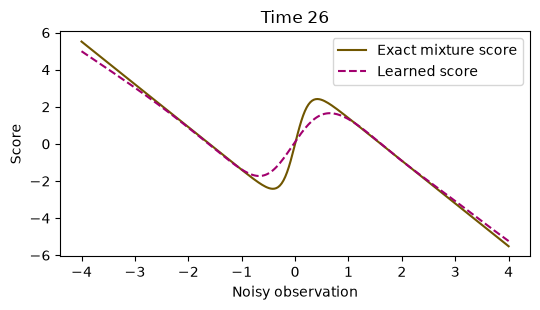

In [3]:
index = 25
grid = torch.linspace(-4, 4, 240)[:, None]
a = float(alpha_bar[index])
means = np.array([-2., 2.]) * np.sqrt(a)
variance = 0.35**2*a + 1-a
g = grid.numpy()
log_components = -0.5*(g-means)**2/variance
responsibilities = np.exp(log_components-log_components.max(1, keepdims=True))
responsibilities /= responsibilities.sum(1, keepdims=True)
exact_score = (responsibilities * (means-g)/variance).sum(1)
with torch.no_grad():
    predicted_score = -model(grid, torch.full((len(grid),), index)).numpy().ravel()/np.sqrt(1-a)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(g.ravel(), exact_score, label='Exact mixture score', color='#705600')
ax.plot(g.ravel(), predicted_score, '--', label='Learned score', color='#a2006e')
ax.set(xlabel='Noisy observation', ylabel='Score', title=f'Time {index+1}')
ax.legend()
plt.tight_layout()
plt.show()

Agreement near high-density regions does not guarantee accuracy in the tails. A global average training loss can conceal local failures important to the reverse trajectory.

## 8.4 · A learned reverse chain

We use the standard noise-prediction mean parameterization

$$
\mu_\theta(x_t,t)=\frac1{\sqrt{\alpha_t}}
\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(x_t,t)\right).
$$

The chosen reverse variance is $\tilde\beta_t=\beta_t(1-\bar\alpha_{t-1})/(1-\bar\alpha_t)$, with $\bar\alpha_0=1$. At the last reverse step, no extra noise is added. Even with this parameterization, finite steps and an imperfect denoiser introduce approximation error.

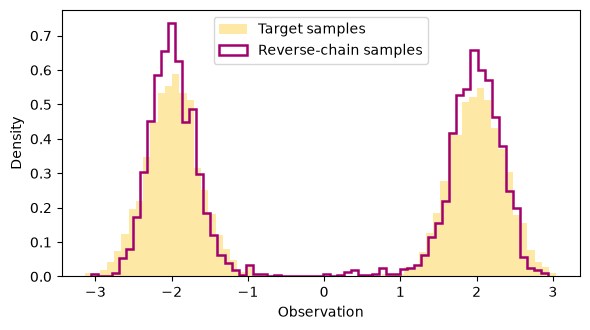

Target / generated positive mass: 0.49966666666666665 0.5023333333333333
Target / generated standard deviation: 2.027 2.001


In [4]:
@torch.no_grad()
def sample_reverse(n):
    model.eval()
    x = torch.randn(n, 1)
    for index in range(T-1, -1, -1):
        t = torch.full((n,), index)
        predicted_noise = model(x, t)
        mean = (x - beta[index]/torch.sqrt(1-alpha_bar[index])*predicted_noise)
        mean = mean / torch.sqrt(alpha[index])
        previous = alpha_bar[index-1] if index > 0 else torch.tensor(1.)
        variance = beta[index]*(1-previous)/(1-alpha_bar[index])
        x = mean + torch.sqrt(variance)*torch.randn_like(x) if index > 0 else mean
    return x

generated = sample_reverse(3000).numpy().ravel()
fresh = data_sample(3000).numpy().ravel()
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(fresh, bins=65, density=True, alpha=0.5, label='Target samples', color='#fed34c')
ax.hist(generated, bins=65, density=True, histtype='step', linewidth=1.8,
        label='Reverse-chain samples', color='#a2006e')
ax.set(xlabel='Observation', ylabel='Density')
ax.legend()
plt.tight_layout()
plt.show()
print('Target / generated positive mass:', (fresh > 0).mean(), (generated > 0).mean())
print('Target / generated standard deviation:', fresh.std().round(3), generated.std().round(3))
assert np.isfinite(generated).all()

Check both modes, central low-density regions, and tail spread. Sampling success is a property of the entire learned reverse chain, not just one denoising MSE. To compare schedules, retrain under each schedule and use the same evaluation function and sample budget.

### Where the reverse mean and variance come from

For $t\ge2$, Gaussian conditioning in the **known forward process** gives

$$
q(x_{t-1}\mid x_t,x_0)=N(\widetilde\mu_t(x_t,x_0),\widetilde\beta_t I),
$$

$$
\widetilde\mu_t(x_t,x_0)=
\frac{\sqrt{\bar\alpha_{t-1}}\beta_t}{1-\bar\alpha_t}x_0
+\frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}x_t.
$$

The clean observation is unavailable during generation. Substitute the denoiser's estimate

$$
\widehat x_0(x_t,t)=\frac{x_t-\sqrt{1-\bar\alpha_t}\epsilon_\theta(x_t,t)}
{\sqrt{\bar\alpha_t}}
$$

from Equation [(8.6)](https://chikuang.github.io/teaching/genai/chapters/08-diffusion.html#equation-eq-clean-estimate) into the posterior mean in Equation [(8.5)](https://chikuang.github.io/teaching/genai/chapters/08-diffusion.html#equation-eq-posterior-mean) and simplify to obtain Equation [(8.4)](https://chikuang.github.io/teaching/genai/chapters/08-diffusion.html#equation-eq-reverse-mean). Then sample $x_{t-1}=\mu_\theta(x_t,t)+\sqrt{\widetilde\beta_t}\,\xi_t$ with fresh independent $\xi_t\sim N(0,I)$; at $t=1$, use the mean without extra noise. These are the Gaussian identities behind the [DDPM update](https://arxiv.org/abs/2006.11239).

Conditioning on both $x_t$ and $x_0$ is crucial: $q(x_{t-1}\mid x_t)$ integrates over unknown clean data and need not be Gaussian. Replacing $x_0$ by a learned estimate and fixing the variance does not make the finite-step reverse transition exact, even if noise prediction reaches its population optimum.

> **Example 8.2 · Read a denoiser output in two ways**
>
> **Setup.** Keep $\bar\alpha_t=0.64$ and observe $x_t=1$. Suppose the trained noise predictor returns $\epsilon_\theta(x_t,t)=0.3$.
>
> **Work it through.** Equation [(8.3)](https://chikuang.github.io/teaching/genai/chapters/08-diffusion.html#equation-eq-noise-score) converts this into estimated score $-0.3/0.6=-0.5$. Equation [(8.6)](https://chikuang.github.io/teaching/genai/chapters/08-diffusion.html#equation-eq-clean-estimate) converts the same output into estimated clean value $(1-0.6(0.3))/0.8=1.025$. The score is a local derivative of log density at the noisy observation; the clean estimate is a location on the original data scale.
>
> **What this shows.** These quantities describe different objects even though they come from the same prediction. Neither says the original clean draw is known. A reverse sampler still needs its schedule, transition mean, and variance; replacing the whole reverse chain by this single clean estimate implements a different procedure.

## 8.5 · Conditioning and the limits of the example

A conditional denoiser receives additional information $c$, such as a class label or text representation, and estimates $\epsilon_\theta(x_t,t,c)$. Guidance methods modify the reverse direction to favor a condition, which can change the diversity–fidelity tradeoff. They do not establish that a requested scientific or factual property is true.

Our one-dimensional example explains noising, denoising, and sampling. It does not reproduce the architecture, latent compression, data scale, or perceptual evaluation of an image-generation system. The statistical questions remain: what distribution is modeled, what is conditioned on, and how is the generated distribution evaluated?

## 8.6 · Exercises and worked solutions

1. **Forward mean and variance:** condition on $x_0$. **Solution:** the mean is $\sqrt{\bar\alpha_t}x_0$ and covariance is $(1-\bar\alpha_t)I$. Unconditionally, the covariance also includes $\bar\alpha_t\operatorname{Cov}(X_0)$.
2. **Score distinction:** which derivative appears in diffusion? **Solution:** the derivative with respect to the noisy observation, not with respect to model parameters. Parameter derivatives are still used when fitting the denoiser by gradient descent.
3. **Regression target:** why is the learned noise not the exact injected noise for each input? **Solution:** several clean/noise pairs can produce the same noisy observation. Squared-error regression estimates their conditional mean, leaving irreducible conditional variance.
4. **Final step:** why is the reverse variance zero at mathematical time one with our choice? **Solution:** $1-\bar\alpha_0=0$. Adding a fresh nonzero noise draw afterward would blur the final samples and implement a different sampler.
5. **Schedule:** if terminal $\bar\alpha_T$ is large, why is starting from $N(0,I)$ questionable? **Solution:** the terminal forward distribution retains substantial structure from the data. The sampler then starts from a distribution different from the one used to train its final-time denoiser.

## 8.7 · Reading and next step

[Denoising Diffusion Probabilistic Models](https://arxiv.org/abs/2006.11239) gives the discrete-time formulation and training/sampling algorithms behind this miniature experiment. Next, [Chapter 9](https://chikuang.github.io/teaching/genai/chapters/09-adaptation-alignment.html) asks how an existing model can be adapted with limited parameters or preference observations.